# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Sissi Wang, Alex Tan, and Sadat Hassan

**Date:** Nov 9th to Nov 11th (11/9 - 11/11)

<class 'pandas.DataFrame'>
RangeIndex: 16814 entries, 0 to 16813
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   sale_date                    16814 non-null  str  
 1   sale_price                   16814 non-null  int64
 2   house_square_feet            16814 non-null  int64
 3   attic_finished_square_feet   16814 non-null  int64
 4   basement_square_feet         16814 non-null  int64
 5   attached_garage_square_feet  16814 non-null  int64
 6   detached_garage_square_feet  16814 non-null  int64
 7   fireplaces                   16814 non-null  int64
 8   hvac_description             16807 non-null  str  
 9   exterior                     16813 non-null  str  
 10  interior                     16807 non-null  str  
 11  stories                      16814 non-null  int64
 12  roof_cover                   16806 non-null  str  
 13  year_built                   16814 non-null  int64
 14  b

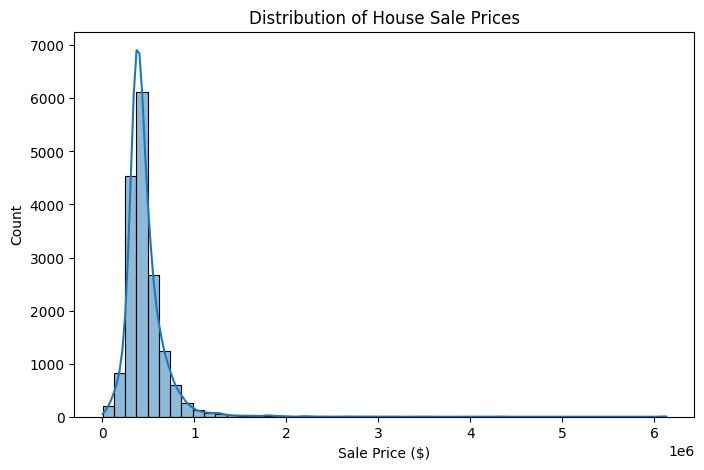

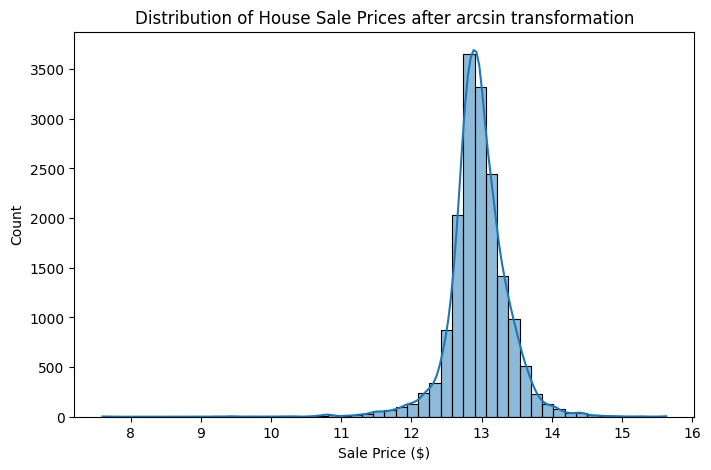

Index(['sale_date', 'sale_price', 'house_square_feet',
       'attic_finished_square_feet', 'basement_square_feet',
       'attached_garage_square_feet', 'detached_garage_square_feet',
       'fireplaces', 'stories', 'year_built', 'bedrooms', 'bathrooms',
       'log_sale_price', 'hvac_description_Electric Baseboard',
       'hvac_description_Floor Wall Furnace',
       'hvac_description_Floor/Wall Furnace', 'hvac_description_Forced Air',
       'hvac_description_Heat Pump', 'hvac_description_Hot Water Baseboard',
       'hvac_description_No Heat', 'hvac_description_None',
       'hvac_description_Warm and Cool Air Zone',
       'exterior_Cedar Finished Cabin', 'exterior_Cedar Unfinished Cabin',
       'exterior_Finished Cottage', 'exterior_Frame Hardboard',
       'exterior_Frame Rustic Log', 'exterior_Frame Siding',
       'exterior_Frame Stucco', 'exterior_Frame Vinyl', 'exterior_Log',
       'exterior_Masonry Common Brick', 'exterior_Masonry Concrete Block',
       'exterior_None',

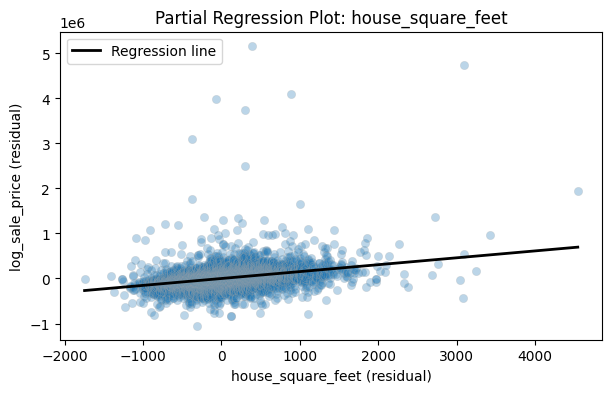

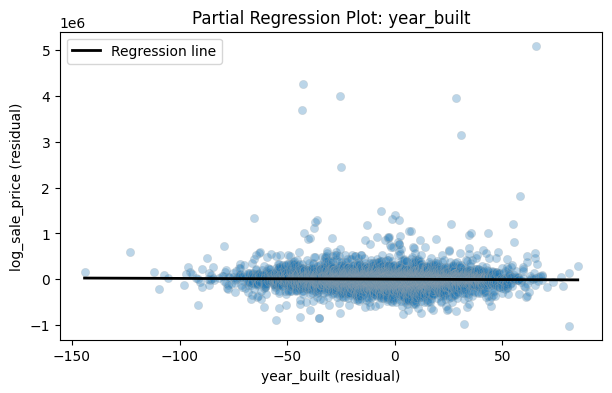

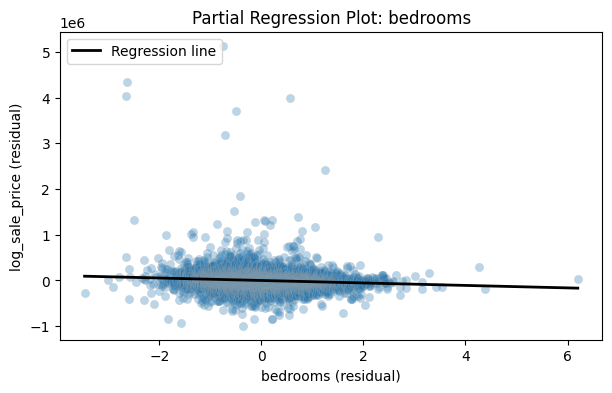

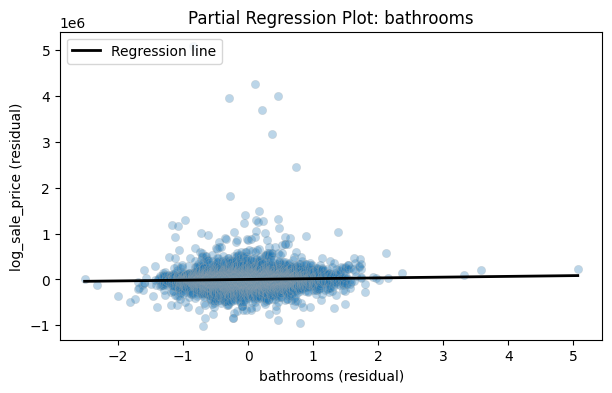

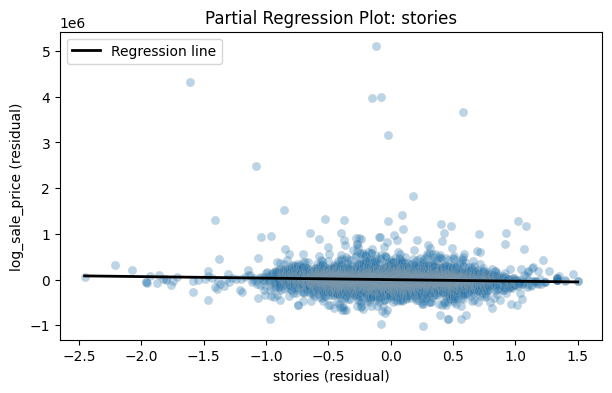

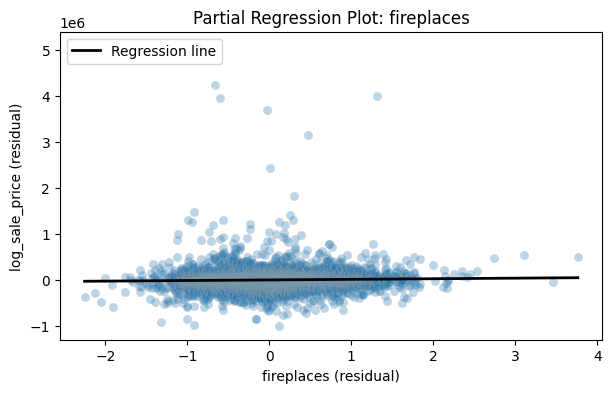

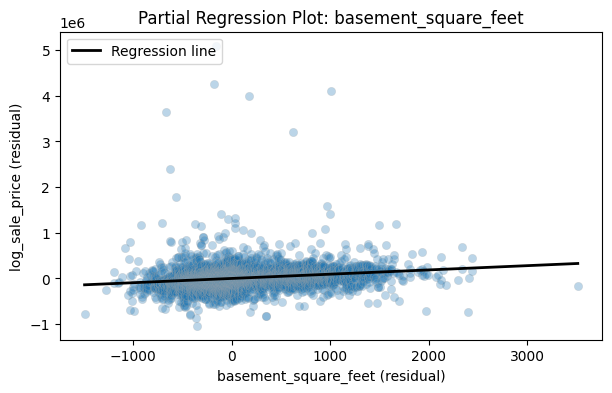

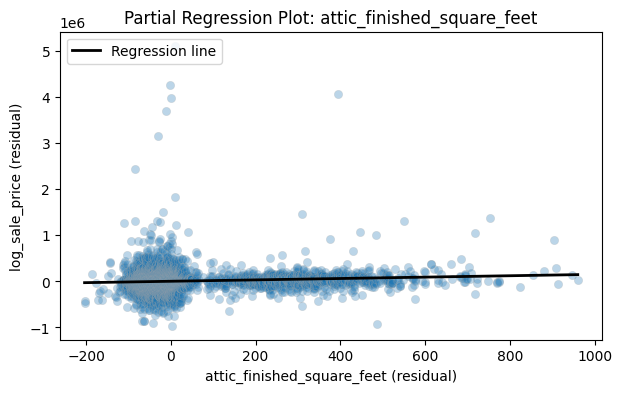

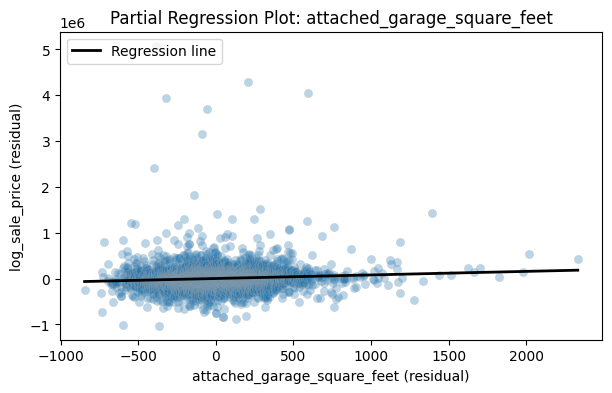

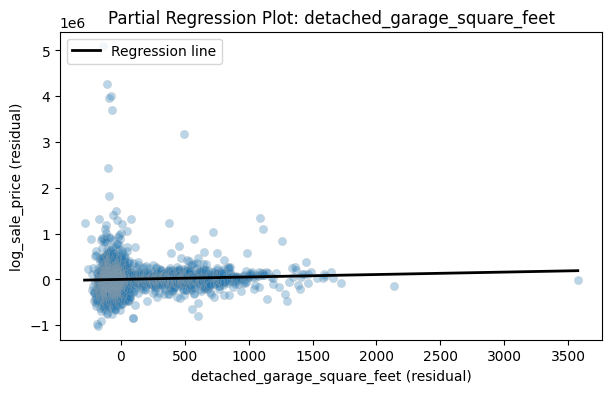

No significant non linearities, the plots look linear so there is not much of a slope
                                               Model  Training RMSE  \
0                               Model 1: Square Feet    195447.6656   
1                  Model 2: Square Feet + Year Built    194856.4420   
2               Model 3: Basic House Characteristics    191453.1938   
3  Model 4: Complex (transformations + interactions)         0.3082   

   Testing RMSE  Training R2  Testing R2  
0   220635.0491       0.2814      0.2625  
1   220271.0857       0.2858      0.2649  
2   216905.6586       0.3105      0.2872  
3        0.3036       0.4772      0.4926  
The complex model performs much better than the simple one as the R^2 value increased a lot to 0.4833
1) cleaned data and log transformed the right-skewed sales price
2) One hot encoded the categorical vars
3) Split 80/20
4) Simple models performed similarly with a test R squared of 0.262 to 0.287
and test RMSE around $216k to $220k. The sim

In [5]:
# Your Phase 1 solution to the problem goes here.

# Step 1
# Clean the data pierce_county_house_sales.csv and perform some EDA and visualization to get to know the data set.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Load dataset
df = pd.read_csv("data/pierce_county_house_sales.csv")

# Basic EDA & Inspection
print(df.info())
print(df.describe())
print(df.columns)

# Check for missing values
print(df.isnull().sum())

# Clean missing values or drop rows where key features are missing
df = df.dropna(subset=["sale_price", "house_square_feet", "year_built"])

# Fill minor missing square footage or counts with 0 where appropriate
fill_zero_cols = [
    "attic_finished_square_feet",
    "basement_square_feet",
    "attached_garage_square_feet",
    "detached_garage_square_feet",
    "fireplaces",
]
for col in fill_zero_cols:
    if col in df.columns:
        df[col] = df[col].fillna(0)

# Visualization: Distribution of Sale Prices
plt.figure(figsize=(8, 5))
sns.histplot(df["sale_price"], kde=True, bins=50)
plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price ($)")
plt.ylabel("Count")
plt.show()

# Log Transform data
df["log_sale_price"] = np.log(df["sale_price"])

plt.figure(figsize=(8, 5))
sns.histplot(df["log_sale_price"], kde=True, bins=50)
plt.title("Distribution of House Sale Prices after arcsin transformation")
plt.xlabel("Sale Price ($)")
plt.ylabel("Count")
plt.show()

# Step 2
# Transform your variables - particularly categorical ones - for use in your regression analysis.

# Handle categorical variables using One-Hot Encoding
categorical_cols = [
    "hvac_description",
    "exterior",
    "interior",
    "roof_cover",
    "waterfront_type",
    "view_quality",
    "utility_sewer",
]

# Loop through each column and fill NaN values
for col in categorical_cols:
  if col in df.columns:
    df[col] = df[col].fillna("None")

# One-hot encode categorical features (dropping first to avoid multicollinearity)
df_encoded = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

print(df_encoded.columns)

# Step 3
# Implement an 80/20 train-test split. Put the test data aside.

from sklearn.model_selection import train_test_split

characteristics = df_encoded.drop(
    columns=['sale_date', 'sale_price', 'log_sale_price']
    )
price = df_encoded['sale_price']
X_train, X_test, y_train, y_test = train_test_split(
   characteristics,
   price,
   test_size=0.2,
   random_state=42,
)

# print("Training data:", X_train.shape)
# print("Testing data:", X_test.shape)

# Step 4
# Build some simple linear models that include no transformations or interactions.
# Fit them, and determine their RMSE and  R2  on the both the training and test sets. Which of your models does the best?

from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import r2_score

# Identify numerical variables
models_features = {
    "Model 1: Square Feet": [
        "house_square_feet"
    ],
    "Model 2: Square Feet + Year Built": [
        "house_square_feet",
        "year_built"
    ],
    "Model 3: Basic House Characteristics": [
        "house_square_feet",
        "year_built",
        "bedrooms",
        "bathrooms"
    ]
}
# Evaluate models
results = []

for name, features in models_features.items():

    # Fit model
    model = LinearRegression()
    model.fit(X_train[features], y_train)

    # Predictions
    train_pred = model.predict(X_train[features])
    test_pred = model.predict(X_test[features])

    # Calculate RMSE
    train_rmse = root_mean_squared_error(y_train, train_pred)
    test_rmse = root_mean_squared_error(y_test, test_pred)

    # Calculate R-squared
    train_r2 = r2_score(y_train, train_pred)
    test_r2 = r2_score(y_test, test_pred)

    # Store results
    results.append({
        "Model": name,
        "Training RMSE": train_rmse,
        "Testing RMSE": test_rmse,
        "Training R2": train_r2,
        "Testing R2": test_r2
    })

# Display results
results_df = pd.DataFrame(results)

print(results_df.round(4))

print("Model 3 is best")

# Step 5
# Make partial correlation plots for each of the numeric variables in your model.
# Do you notice any significant non-linearities?

# Numeric variables to plot
numeric_cols = [
    "house_square_feet", "year_built", "bedrooms", "bathrooms", "stories",
    "fireplaces", "basement_square_feet", "attic_finished_square_feet",
    "attached_garage_square_feet", "detached_garage_square_feet",
]

# Every column in the training data (numeric + dummy variables)
all_features = list(X_train.columns)

def slr(x, y):
    x_bar, y_bar = np.mean(x), np.mean(y)
    b1 = np.inner(x - x_bar, y - y_bar) / np.inner(x - x_bar, x - x_bar)
    b0 = y_bar - b1 * x_bar
    y_hat = b0 + b1 * x
    return {"b0": b0, "b1": b1, "y_hat": y_hat, "residuals": y - y_hat}

for col in numeric_cols:

    # others
    others = []
    for feature in all_features:
        if feature != col:
            others.append(feature)

    # Subtract what the other features predict from both the variable and the outcome
    x_model = LinearRegression().fit(X_train[others], X_train[col])
    y_model = LinearRegression().fit(X_train[others], y_train)
    r_x = X_train[col] - x_model.predict(X_train[others])
    r_y = y_train - y_model.predict(X_train[others])

    # Sort by r_x
    partial = pd.DataFrame({"r_x": r_x, "r_y": r_y}).sort_values("r_x")

    # Fit a straight line to the residuals
    line = slr(partial["r_x"], partial["r_y"])

    # Plot residuals and the fitted line
    plt.figure(figsize=(7, 4))
    sns.scatterplot(data=partial, x="r_x", y="r_y", alpha=0.3, edgecolor="darkgrey")
    plt.plot(partial["r_x"], line["y_hat"], color="black", linewidth=2,
             label="Regression line")
    plt.title("Partial Regression Plot: " + col)
    plt.xlabel(col + " (residual)")
    plt.ylabel("log_sale_price (residual)")
    plt.legend(loc="upper left")
    plt.show()

print("No significant non linearities, the plots look linear so there is not much of a slope")

# Step 6
# Include transformations and interactions of your variables, and build a more complex model that reflects your ideas
# about how the features of the asset determine its value. Determine its RMSE and  R2  on the training and test sets.
# How does the more complex model your build compare to the simpler ones?

cha = df_encoded.drop(
    columns=['sale_date', 'sale_price', 'log_sale_price']
    )
pri = df_encoded['log_sale_price']
X_train_log, X_test_log, y_train_log, y_test_log = train_test_split(
   cha,
   pri,
   test_size=0.2,
   random_state=42,
)

# Newest year
newest_year = X_train_log["year_built"].max()

#transformed and interaction features
def add_features(data):
    new = data.copy()

    new["age"] = newest_year - new["year_built"]
    new["age_squared"] = new["age"] ** 2

    # arcsinh compresses long tails and accepts zeros
    new["house_square_feet_ihs"] = np.arcsinh(new["house_square_feet"])
    new["basement_square_feet_ihs"] = np.arcsinh(new["basement_square_feet"])
    new["attic_finished_square_feet_ihs"] = np.arcsinh(new["attic_finished_square_feet"])
    new["attached_garage_square_feet_ihs"] = np.arcsinh(new["attached_garage_square_feet"])
    new["detached_garage_square_feet_ihs"] = np.arcsinh(new["detached_garage_square_feet"])

    # Interactions examples like how number of bathrooms and age may differ in importance for bigger houses
    new["sqft_x_bathrooms"] = new["house_square_feet_ihs"] * new["bathrooms"]
    new["sqft_x_age"] = new["house_square_feet_ihs"] * new["age"]

    return new

# same transformations for training and test
X_train_c = add_features(X_train_log)
X_test_c = add_features(X_test_log)

# complex features - transformed numerics, interactions, and original counts
complex_features = [
    "house_square_feet_ihs", "basement_square_feet_ihs",
    "attic_finished_square_feet_ihs", "attached_garage_square_feet_ihs",
    "detached_garage_square_feet_ihs", "age", "age_squared",
    "sqft_x_bathrooms", "sqft_x_age",
    "bedrooms", "bathrooms", "stories", "fireplaces",
]

for feature in all_features:
    if feature not in numeric_cols:
        complex_features.append(feature)

complex_model = LinearRegression()
complex_model.fit(X_train_c[complex_features], y_train_log)

train_pred = complex_model.predict(X_train_c[complex_features])
test_pred = complex_model.predict(X_test_c[complex_features])

# rmse and r2
train_rmse = root_mean_squared_error(y_train_log, train_pred)
test_rmse = root_mean_squared_error(y_test_log, test_pred)
train_r2 = r2_score(y_train_log, train_pred)
test_r2 = r2_score(y_test_log, test_pred)

# add to results
results.append({
    "Model": "Model 4: Complex (transformations + interactions)",
    "Training RMSE": train_rmse,
    "Testing RMSE": test_rmse,
    "Training R2": train_r2,
    "Testing R2": test_r2
})
results_df = pd.DataFrame(results)
print(results_df.round(4))

print("The complex model performs much better than the simple one as the R^2 value increased a lot to 0.4833")

# Step 7
# Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
print("1) cleaned data and log transformed the right-skewed sales price\n"
"2) One hot encoded the categorical vars\n"
"3) Split 80/20\n"
"4) Simple models performed similarly with a test R squared of 0.262 to 0.287\n"
"and test RMSE around $216k to $220k. The simple models are underfit. Model 3 was the best simple model.\n"
"5) Additional features barely changed R squared (only moving from 0.2625 to 0.2872), showing that adding raw variables is not enough.\n"
"6) The complex model with transformations and interactions improved test R^2 to 0.483 and test RMSE to 0.306 on the log scale.\n"
"The train and test curves were nearly equal, so there was no overfitting overall.")

print("Adding raw vars is not enough as Model 1 to Model 3 barely changed r squared\n"
"making them underfit regardless. What has a greater impact overall are feature transformations and interactions,\n"
"which increased r^2 from 0.262 to 0.483. There was no overfitting in the complex model since train basically equalled test.")

# Step 8
# Use sklearn.linear_model.Lasso to regularize your model and select the most predictive features.
# Which does it select? What are the RMSE and R2?

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.model_selection import KFold, GridSearchCV

#lasso from lecture 11
lasso_X_train = X_train_c[complex_features]
lasso_X_test = X_test_c[complex_features]

model = make_pipeline(
    StandardScaler(),
    Lasso(max_iter=20000)
)

cv = KFold(n_splits=5, shuffle=True, random_state=3001)

search = GridSearchCV(
    model, {"lasso__alpha": [0.00001, 0.0001, 0.001, 0.01, 0.1]},
    cv=cv, scoring="neg_root_mean_squared_error", error_score="raise"
)
search.fit(lasso_X_train, y_train_log);

best_model = search.best_estimator_

# predictions
train_pred = best_model.predict(lasso_X_train)
test_pred = best_model.predict(lasso_X_test)

# rmse and r squared
lasso_train_rmse = root_mean_squared_error(y_train_log, train_pred)
lasso_test_rmse = root_mean_squared_error(y_test_log, test_pred)
lasso_train_r2 = r2_score(y_train_log, train_pred)
lasso_test_r2 = r2_score(y_test_log, test_pred)

print("Training RMSE:", round(lasso_train_rmse, 4), " Testing RMSE:", round(lasso_test_rmse, 4))
print("Training R2:", round(lasso_train_r2, 4), " Testing R2:", round(lasso_test_r2, 4))

lasso = best_model.named_steps["lasso"]

print(pd.Series(lasso.coef_, index=complex_features).round(4))

print("It kept the features with nonzero constanst, which was 59/62 shown in the print.")
print("The most predictive are sqft_x_bathrooms and bathrooms with 0.4499 and -0.3360.")
print("The training rmse was 0.3081, the training r2 was 0.4777")
print("the testing rmse was 0.3061, the testing r2 was 0.4843")



## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]